# 5. Geração

**Pergunta deste notebook:** como um modelo que só prevê "o próximo token" vira um gerador de músicas, e que escolhas fazemos na hora de sortear?

A receita (`src/sample.py`) é um laço:

1. começa com o token `BOS` (início de música);
2. o modelo devolve a probabilidade de cada token ser o próximo;
3. **sorteia** um token dessa distribuição e o acrescenta à sequência;
4. repete até sair `EOS` (fim de música) ou até o limite de 1.828 tokens;
5. destokeniza a sequência e tem-se uma música.

As músicas saem do zero, sem nenhuma música real como ponto de partida.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import nbkit as k

k.estilo()
modelo, tok, ckpt = k.carregar_modelo("grid_block")
print(f"pesos da época {ckpt['epoch']}, vocabulário de {tok.vocab_size} tokens")

pesos da época 8, vocabulário de 1250 tokens


## As escolhas do sorteio

O passo 3 tem dois botões:

- **Temperatura (T):** achata (T > 1) ou afia (T < 1) a distribuição antes do sorteio. T = 1 usa a distribuição do modelo como ela é.
- **Top-k:** só os k tokens mais prováveis participam do sorteio. Corta a "cauda" de tokens muito improváveis, que de vez em quando seriam sorteados e estragariam a música.

Veja o efeito na distribuição do próximo token, logo depois do começo de uma música:

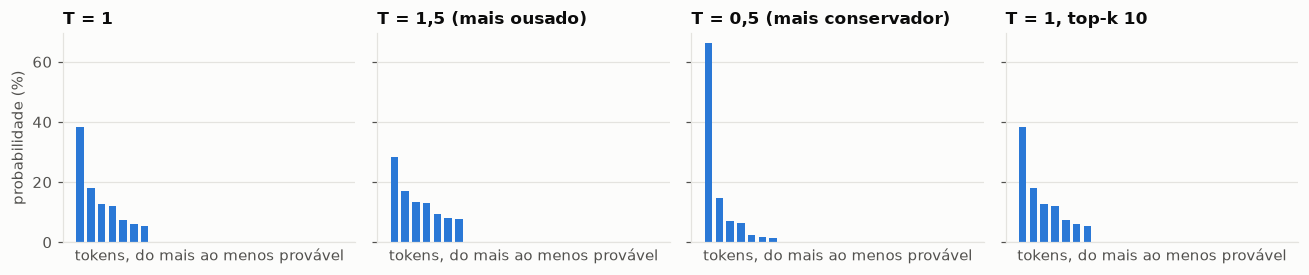

In [2]:
prefixo = tok.encode_song_to_ids(k.musicas_reais(155)[154])[:9]
with torch.no_grad():
    logits, _ = modelo(torch.tensor([prefixo]))
z = logits[0, -1]
ordem = torch.argsort(z, descending=True)[:25]

casos = [("T = 1", torch.softmax(z, -1)), ("T = 1,5 (mais ousado)", torch.softmax(z / 1.5, -1)),
         ("T = 0,5 (mais conservador)", torch.softmax(z / 0.5, -1))]
zk = z.masked_fill(z < torch.topk(z, 10).values[-1], float("-inf"))
casos.append(("T = 1, top-k 10", torch.softmax(zk, -1)))

fig, axes = plt.subplots(1, 4, figsize=(12, 2.6), sharey=True)
for ax, (titulo, p) in zip(axes, casos):
    ax.bar(range(25), p[ordem].numpy() * 100, color=k.AZUL, width=0.7)
    ax.set_title(titulo, loc="left"); ax.set_xlabel("tokens, do mais ao menos provável")
    ax.set_xticks([]); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("probabilidade (%)")
fig.tight_layout()
plt.show()

## Gerando ao vivo

Geramos três músicas com cada configuração (a função `gerar` é a do `sample.py`, sem mudanças). Leva alguns segundos em CPU.

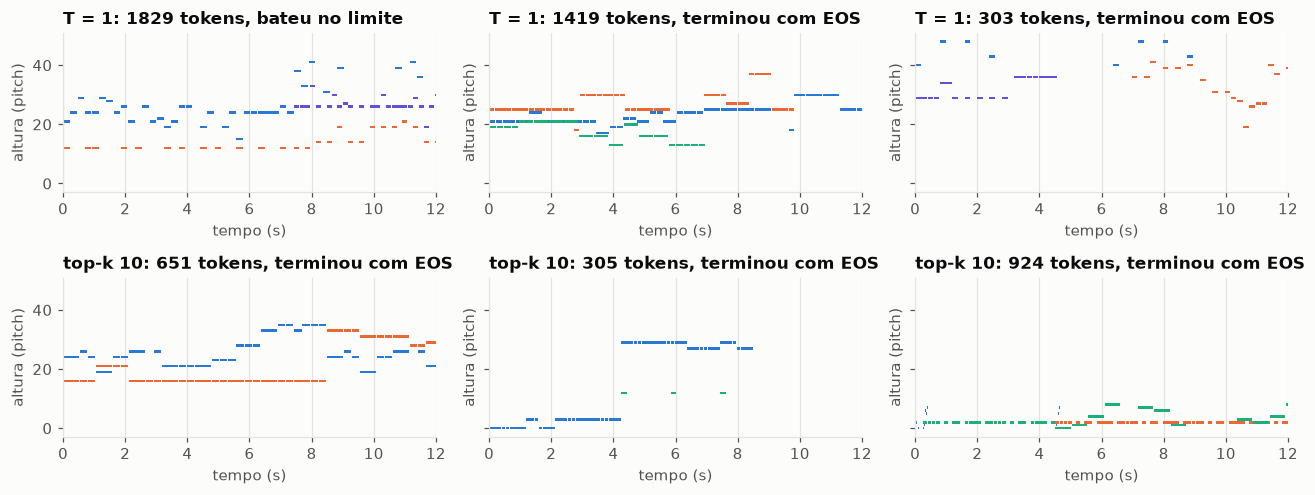

In [3]:
t1 = k.gerar(modelo, tok, n=3, temperatura=1.0, top_k=0, seed=42)
k10 = k.gerar(modelo, tok, n=3, temperatura=1.0, top_k=10, seed=42)

fig, axes = plt.subplots(2, 3, figsize=(12, 4.6), sharey=True)
for linha, (rotulo, musicas) in enumerate([("T = 1", t1), ("top-k 10", k10)]):
    for ax, m in zip(axes[linha], musicas):
        fim = "terminou com EOS" if m["token_ids"][-1] == tok.eos_id else "bateu no limite"
        k.piano_roll(m, ax, segundos=12, legenda=False,
                     titulo=f"{rotulo}: {len(m['token_ids'])} tokens, {fim}")
fig.tight_layout()
plt.show()

Ouça uma de cada (8 segundos):

In [4]:
k.tocar(t1[0])

In [5]:
k.tocar(k10[0])

## As 1.854 músicas geradas para a avaliação

Para avaliar, geramos no cluster 1.854 músicas por configuração (o tamanho do conjunto de teste), com semente 42. Elas estão em `artefatos/predicoes-teste/`. Cada linha já traz a música decodificada e também os `token_ids`.

Duas coisas para conferir: o modelo **termina** as músicas sozinho (gera `EOS`)? E elas têm **duração** parecida com a das reais?

In [6]:
reais = k.musicas_reais()
dur_real = np.array([k.duracao(m) for m in reais])
linhas, duracoes = [], {}
for sistema in ("grid_block-k10", "grid_block-t1", "nlm-k10", "nlm-t1"):
    ms = k.musicas_geradas(sistema)
    eos = np.mean([m["token_ids"][-1] == 2 for m in ms])
    duracoes[sistema] = np.array([k.duracao(m) for m in ms])
    linhas.append({"sistema": k.nome("lstm-" + sistema), "músicas": len(ms),
                   "terminam com EOS": f"{100 * eos:.0f}%",
                   "duração mediana (s)": k.br(np.median(duracoes[sistema]), 1)})
linhas.append({"sistema": "real (teste)", "músicas": len(reais), "terminam com EOS": "",
               "duração mediana (s)": k.br(np.median(dur_real), 1)})
k.tabela(linhas)

| sistema | músicas | terminam com EOS | duração mediana (s) |
|---|---|---|---|
| LSTM grid_block, top-k 10 | 1854 | 94% | 19,8 |
| LSTM grid_block, T = 1 | 1854 | 89% | 19,1 |
| LSTM nlm, top-k 10 | 1854 | 72% | 33,8 |
| LSTM nlm, T = 1 | 1854 | 84% | 19,6 |
| real (teste) | 1854 |  | 12,7 |

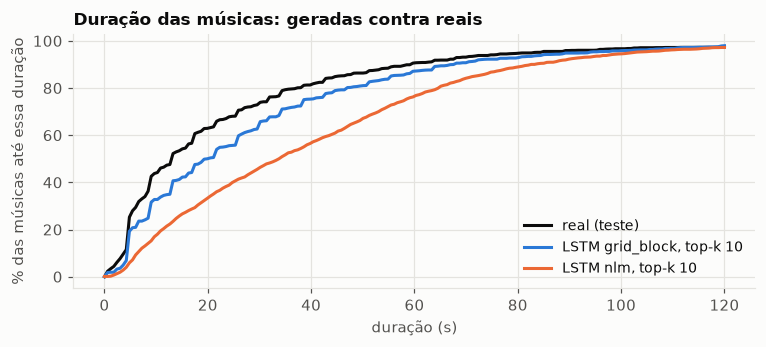

In [7]:
fig, ax = plt.subplots(figsize=(8, 3))
grade = np.linspace(0, 120, 200)
for rotulo, d, cor in [("real (teste)", dur_real, k.TINTA), ("LSTM grid_block, top-k 10", duracoes["grid_block-k10"], k.AZUL),
                       ("LSTM nlm, top-k 10", duracoes["nlm-k10"], k.LARANJA)]:
    ax.plot(grade, [(d <= g).mean() * 100 for g in grade], lw=2, color=cor, label=rotulo)
ax.set_xlabel("duração (s)"); ax.set_ylabel("% das músicas até essa duração")
ax.set_title("Duração das músicas: geradas contra reais", loc="left")
ax.legend(frameon=False, fontsize=9)
plt.show()

Leitura:

- A maioria das músicas termina sozinha, com `EOS`. As demais são cortadas no limite de 1.828 tokens.
- As geradas tendem a ser **mais longas** que as reais: o modelo gera menos vinhetas de poucos segundos do que existe no teste.
- O grid_block fica mais perto das reais. O nlm com top-k 10 é o que menos termina com `EOS` (72%) e o que gera as músicas mais longas.

## O que decidimos e por quê

- Geramos com **T = 1** (a distribuição do modelo, sem mexer) e com **top-k 10** (cortando a cauda). São as duas opções que o `sample.py` oferece.
- Com o grid_block, o top-k 10 deu as músicas mais parecidas com as reais (notebook 6), e por isso é a sugestão de sistema principal.
- Ressalva: o valor k = 10 **não foi ajustado na validação**; foi uma escolha única. Ajustar k e T na validação é uma melhoria possível.

**Experimente:** gere com `temperatura=0.7` ou `top_k=3` e ouça; troque `"grid_block"` por `"nlm"` em `carregar_modelo`; mude a `seed`.

Anterior: [4. Treino](04_treino.ipynb) · Próximo: [6. Avaliação](06_avaliacao.ipynb).